## Stage 1 — Clustering NBA players using traditional box-score stats

### Data and player sample

I used 2024–25 NBA regular-season per-game statistics from the NBA Stats API. The source dataset contained 569 player records and 69 columns. I verified that each `PLAYER_ID` appeared once and that there were no missing values. I defined core rotation players as those who played **at least 40 games** and averaged **at least 15 minutes per game**. These criteria left **295 players for clustering**. Player names were retained for identifying and reviewing players after clustering.


In [132]:
import pandas as pd
import numpy as py
import matplotlib.pyplot as plt
import seaborn as sns
from nba_api.stats.endpoints import LeagueDashPlayerStats

In [133]:
players = LeagueDashPlayerStats(
    season="2024-25",
    season_type_all_star="Regular Season",
    measure_type_detailed_defense="Base",
    per_mode_detailed="PerGame",
    timeout=60,
).get_data_frames()[0]

players.to_csv("nba_players_2024_25_traditional_per_game.csv", index=False)

,PLAYER_NAME,TEAM_ABBREVIATION,GP,MIN
0,A.J. Lawson,TOR,26,18.7
1,AJ Green,MIL,73,22.7
2,AJ Johnson,WAS,29,22.0
3,Aaron Gordon,DEN,51,28.4
4,Aaron Holiday,HOU,62,12.8


In [134]:
players.head()

,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK,NBA_FANTASY_PTS_RANK,DD2_RANK,TD3_RANK,WNBA_FANTASY_PTS_RANK,FP_HIGH_SCORE_RANK,TEAM_COUNT
0,1630639,A.J. Lawson,A.J.,1610612761,TOR,24.0,26,14,12,0.538,...,247,207,219,300,292,159,44,281,303,1
1,1631260,AJ Green,AJ,1610612749,MIL,25.0,73,44,29,0.603,...,136,394,278,83,342,281,44,318,345,1
2,1642358,AJ Johnson,AJ,1610612764,WAS,20.0,29,8,21,0.276,...,239,321,273,522,332,281,44,328,311,2
3,203932,Aaron Gordon,Aaron,1610612743,DEN,29.0,51,33,18,0.647,...,277,89,98,26,127,134,44,124,126,1
4,1628988,Aaron Holiday,Aaron,1610612745,HOU,28.0,62,39,23,0.629,...,413,350,363,142,422,281,44,403,415,1


In [135]:
players.shape

(569, 69)

In [136]:
players.columns

Index(['PLAYER_ID', 'PLAYER_NAME', 'NICKNAME', 'TEAM_ID', 'TEAM_ABBREVIATION',
       'AGE', 'GP', 'W', 'L', 'W_PCT', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M',
       'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST',
       'TOV', 'STL', 'BLK', 'BLKA', 'PF', 'PFD', 'PTS', 'PLUS_MINUS',
       'NBA_FANTASY_PTS', 'DD2', 'TD3', 'WNBA_FANTASY_PTS', 'FP_HIGH_SCORE',
       'GP_RANK', 'W_RANK', 'L_RANK', 'W_PCT_RANK', 'MIN_RANK', 'FGM_RANK',
       'FGA_RANK', 'FG_PCT_RANK', 'FG3M_RANK', 'FG3A_RANK', 'FG3_PCT_RANK',
       'FTM_RANK', 'FTA_RANK', 'FT_PCT_RANK', 'OREB_RANK', 'DREB_RANK',
       'REB_RANK', 'AST_RANK', 'TOV_RANK', 'STL_RANK', 'BLK_RANK', 'BLKA_RANK',
       'PF_RANK', 'PFD_RANK', 'PTS_RANK', 'PLUS_MINUS_RANK',
       'NBA_FANTASY_PTS_RANK', 'DD2_RANK', 'TD3_RANK', 'WNBA_FANTASY_PTS_RANK',
       'FP_HIGH_SCORE_RANK', 'TEAM_COUNT'],
      dtype='object')

In [158]:
print(players["PLAYER_ID"].nunique() == len(players))
print(players.isna().sum().sum() == 0)

True
True


In [137]:
core_players = players.loc[(players['GP'] >= 40) & (players['MIN'] >= 15)]
core_players.head()

,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK,NBA_FANTASY_PTS_RANK,DD2_RANK,TD3_RANK,WNBA_FANTASY_PTS_RANK,FP_HIGH_SCORE_RANK,TEAM_COUNT
1,1631260,AJ Green,AJ,1610612749,MIL,25.0,73,44,29,0.603,...,136,394,278,83,342,281,44,318,345,1
3,203932,Aaron Gordon,Aaron,1610612743,DEN,29.0,51,33,18,0.647,...,277,89,98,26,127,134,44,124,126,1
5,1630174,Aaron Nesmith,Aaron,1610612754,IND,25.0,45,29,16,0.644,...,52,169,147,53,193,281,44,180,207,1
6,1630598,Aaron Wiggins,Aaron,1610612760,OKC,26.0,76,62,14,0.816,...,349,326,146,14,187,159,44,177,197,1
9,1641737,Adem Bona,Adem,1610612755,PHI,22.0,58,12,46,0.207,...,134,192,355,404,312,134,44,334,320,1


In [138]:
core_players.shape

(295, 69)

### Feature selection and preprocessing

I selected 17 numeric features from the traditional box score:

- **Scoring volume and shooting percentages** — points, field-goal attempts and percentage, three-point attempts and percentage, free-throw attempts and percentage
- **Playmaking and ball security** — assists and turnovers
- **Rebounding** — offensive and defensive rebounds
- **Other box-score production** — steals, blocks, blocks against, personal fouls, personal fouls drawn, and plus-minus

I used offensive and defensive rebounds separately to preserve the distinction between them. Total rebounds were omitted because they are the sum of those two columns. I included both attempts and percentages to capture how often players shoot and how often they convert. Free-throw attempts describe how often players get to the line, while free-throw percentage describes how often they convert once there.

The feature set represents offense in more detail than defense. Several columns reflect related aspects of scoring volume, and standardization still lets those columns contribute separately to the distance calculation. Defensive box-score events capture some contributions, while matchup responsibilities and off-ball defense are harder to see in these data.

During exploratory analysis, I examined feature skewness and inspected the tails for blocks and three-point percentage. The high block values corresponded to actual player performances, while the recorded zero three-point percentages occurred among players with very few or possibly no attempts. I kept the original distributions and applied `StandardScaler` to the selected features before fitting K-means. The exploratory review focused on distributions and selected extreme values.

In [139]:
feature_columns = ['PTS', 'FGA', 'FG_PCT', 'FG3A', 'FG3_PCT', 'FTA', 'FT_PCT', 'AST', 'OREB', 'DREB', 'STL', 'BLK', 'BLKA', 'PF', 'PFD', 'TOV', 'PLUS_MINUS']
core_players[feature_columns].describe()

,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
count,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000,295.000000
mean,12.584068,9.810847,0.471383,4.096610,0.330122,2.405763,0.775119,2.888814,1.173898,3.589153,0.872203,0.521695,0.531864,1.960339,2.058644,1.461356,0.096271
std,6.085752,4.433064,0.066017,2.371096,0.100036,1.768585,0.089832,1.929006,0.817140,1.742394,0.353563,0.440011,0.286787,0.547431,1.345711,0.808626,3.747555
min,3.100000,2.700000,0.323000,0.000000,0.000000,0.200000,0.456000,0.500000,0.200000,1.000000,0.200000,0.000000,0.000000,0.600000,0.300000,0.300000,-9.900000
25%,8.200000,6.500000,0.429000,2.500000,0.319000,1.100000,0.717000,1.500000,0.600000,2.400000,0.600000,0.200000,0.300000,1.600000,1.100000,0.900000,-2.250000
50%,10.600000,8.400000,0.459000,4.100000,0.354000,1.800000,0.785000,2.200000,0.900000,3.100000,0.800000,0.400000,0.500000,2.000000,1.700000,1.200000,-0.300000
75%,16.250000,12.400000,0.499000,5.650000,0.386000,3.100000,0.836000,4.000000,1.500000,4.400000,1.100000,0.600000,0.700000,2.300000,2.700000,1.900000,2.650000
max,32.700000,21.800000,0.722000,11.200000,0.456000,10.600000,1.000000,11.600000,4.600000,10.100000,3.000000,3.800000,1.400000,3.500000,7.600000,4.700000,12.100000


In [140]:
core_players.nlargest(15, "BLK")[["PLAYER_NAME", "BLK", "GP", "MIN"]]

,PLAYER_NAME,BLK,GP,MIN
550,Victor Wembanyama,3.8,46,33.2
554,Walker Kessler,2.4,58,30.0
28,Anthony Davis,2.2,51,33.4
411,Myles Turner,2.0,72,30.2
62,Brook Lopez,1.9,80,31.8
115,Daniel Gafford,1.8,57,21.5
148,Donovan Clingan,1.6,67,19.8
169,Evan Mobley,1.6,71,30.5
17,Alex Sarr,1.5,67,27.1
249,Jaren Jackson Jr.,1.5,74,29.8


In [166]:
zero_pct = core_players.loc[
    core_players["FG3_PCT"] == 0,
    ["PLAYER_NAME", "FG3A", "FG3_PCT", "GP"],
]

display(zero_pct.sort_values("FG3A", ascending=False))

,PLAYER_NAME,FG3A,FG3_PCT,GP
197,Isaiah Hartenstein,0.3,0.0,57
388,Mason Plumlee,0.1,0.0,74
251,Jarrett Allen,0.1,0.0,82
253,Jaxson Hayes,0.1,0.0,56
410,Moussa Diabaté,0.1,0.0,71
383,Mark Williams,0.1,0.0,44
9,Adem Bona,0.0,0.0,58
524,Trayce Jackson-Davis,0.0,0.0,62
476,Rudy Gobert,0.0,0.0,72
436,Oso Ighodaro,0.0,0.0,61


In [141]:
from scipy.stats import skew
skew_df = pd.DataFrame(columns = ['Feature Name', 'Skewness'])

for feature in feature_columns:
    skewness = skew(core_players[feature])
    skew_df = skew_df._append({'Feature Name': feature, 'Skewness': skewness}, ignore_index=True)

skew_df

/var/folders/fx/_t32rsys3w1bllr_tvvv45w00000gn/T/ipykernel_58287/2405168708.py:6: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  skew_df = skew_df._append({'Feature Name': feature, 'Skewness': skewness}, ignore_index=True)


,Feature Name,Skewness
0,PTS,0.943603
1,FGA,0.806214
2,FG_PCT,1.199405
3,FG3A,0.320233
4,FG3_PCT,-2.239010
5,FTA,1.424522
6,FT_PCT,-0.616472
7,AST,1.380391
8,OREB,1.411093
9,DREB,1.368586


In [142]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
stats_normalized = scaler.fit_transform(core_players[feature_columns])

### Choosing the number of clusters

I used an inertia elbow curve and silhouette scores to compare candidate solutions. The elbow was clearest at **three clusters**. The silhouette scores for two and three clusters were nearly identical (**0.303 and 0.302**), while the five-cluster solution scored **0.193**.

I kept **three clusters as the statistical baseline** and selected **five clusters for the detailed Stage 1 analysis**. The three-cluster solution captured broad differences in scoring, creation, and interior production. Its largest group contained **169 of the 295 players**. The five-cluster solution gave a more detailed view, particularly by separating high-scoring rebounders and shot blockers from high-volume perimeter creators. Both groups averaged roughly **22–23 points per game**, but their rebounding, three-point volume, and assist profiles differed.

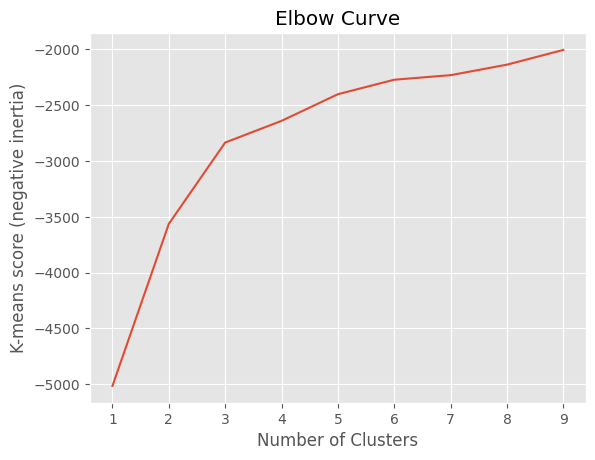

In [165]:
from sklearn.cluster import KMeans

cluster_iteration = range(1,10)
scores = []

for cluster_number in cluster_iteration:
    K_Means = KMeans(n_clusters = cluster_number, random_state = 42)
    scores.append(K_Means.fit(stats_normalized).score(stats_normalized))

plt.plot(cluster_iteration,scores)
plt.xlabel('Number of Clusters')
plt.ylabel('K-means score (negative inertia)')
plt.title('Elbow Curve')
plt.xticks(cluster_iteration)
plt.style.use('ggplot')
plt.show()

In [145]:
from sklearn.metrics import silhouette_score

cluster_iteration = range(2,10)  # Start from at least 2 clusters (Silhouette Score Requirement)
inertias = []

for cluster_number in cluster_iteration:
    K_Means = KMeans(n_clusters=cluster_number, random_state=42)
    K_Means.fit(stats_normalized)
    clustered_labels = K_Means.labels_
    
    silhouette_avg = silhouette_score(stats_normalized,clustered_labels)
    print(f'For n_clusters={cluster_number}, the Silhouette score is {silhouette_avg}')

For n_clusters=2, the Silhouette score is 0.30308717502523264
For n_clusters=3, the Silhouette score is 0.302441784727848
For n_clusters=4, the Silhouette score is 0.2768517034342675
For n_clusters=5, the Silhouette score is 0.1929008028521612
For n_clusters=6, the Silhouette score is 0.14362724599215543
For n_clusters=7, the Silhouette score is 0.12316448632821872
For n_clusters=8, the Silhouette score is 0.11510713126175802
For n_clusters=9, the Silhouette score is 0.12168242402531734


### Interpreting the five clusters

I calculated each cluster’s average stats in their original units and reviewed a random sample of ten players per cluster. I used the full-cluster averages to develop working labels and the samples to see where those labels fit individual players.

| Cluster | Players | Working label |
|---|---:|---|
| 0 | 123 | Lower-volume perimeter scorers |
| 1 | 13 | High-scoring rebounders and shot blockers |
| 2 | 49 | High-volume perimeter creators |
| 3 | 74 | Mid-volume contributors |
| 4 | 36 | Lower-volume rebounders and shot blockers |

The results showed both familiar roles and cross-position similarities. Cluster 4 resembled a traditional interior group, while Cluster 3 grouped players such as Fred VanVleet, Aaron Gordon, and Nikola Vučević despite their different positions. Individual assignments also showed the limits of the labels. Shai Gilgeous-Alexander shared parts of Cluster 1’s scoring profile while rebounding much less than its average. Jimmy Butler fit Cluster 2’s assist profile while attempting fewer threes and more free throws.

In [146]:
clustered_players = core_players.copy()

for k in (3, 5):
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(stats_normalized)
    clustered_players[f"cluster_{k}"] = labels
    
    groups = clustered_players.groupby(f"cluster_{k}")
    profile = groups[feature_columns].mean().round(2)
    profile.insert(0, "n_players", groups.size())

    print(f"\nk = {k} | silhouette = {silhouette_score(stats_normalized, labels):.3f}")
    display(profile)

display(pd.crosstab(
    clustered_players["cluster_3"],
    clustered_players["cluster_5"],
))


k = 3 | silhouette = 0.302


,n_players,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
cluster_3,,,,,,,,,,,,,,,,,,
0,169,9.40,7.69,0.45,3.96,0.36,1.38,0.78,2.13,0.86,2.71,0.78,0.36,0.39,1.76,1.25,1.03,-0.29
1,40,9.32,6.64,0.59,0.54,0.14,2.11,0.67,1.85,2.52,4.95,0.70,1.00,0.50,2.27,1.90,1.22,-0.30
2,86,20.36,15.46,0.47,6.01,0.36,4.57,0.81,4.86,1.17,4.69,1.13,0.61,0.83,2.21,3.71,2.42,1.04



k = 5 | silhouette = 0.193


,n_players,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
cluster_5,,,,,,,,,,,,,,,,,,
0,123,8.46,6.94,0.44,3.84,0.36,1.18,0.79,1.93,0.77,2.42,0.71,0.32,0.34,1.60,1.07,0.89,-0.32
1,13,23.20,16.35,0.53,3.97,0.36,5.78,0.78,4.45,2.33,7.56,1.12,1.31,0.92,2.61,4.99,2.50,4.41
2,49,22.08,16.81,0.46,7.05,0.36,4.93,0.84,5.59,0.86,4.22,1.10,0.41,0.87,2.03,3.90,2.64,0.73
3,74,12.91,10.40,0.46,4.38,0.35,2.34,0.77,2.95,1.17,3.74,1.05,0.54,0.59,2.27,2.06,1.57,-0.24
4,36,9.26,6.52,0.60,0.41,0.13,2.07,0.67,1.80,2.58,4.98,0.66,1.04,0.48,2.23,1.86,1.19,-0.22


cluster_5,0,1,2,3,4
cluster_3,,,,,
0,123,0,0,46,0
1,0,0,0,4,36
2,0,13,49,24,0


### Why I Chose Five Clusters for Stage 1

I compared the average stat profiles, sampled players from both solutions, and used a cross-tabulation to see where players moved. The three-cluster solution captured broad differences in scoring volume, playmaking, and rebounding. Its largest group contained 169 of the 295 players. In the five-cluster solution, 123 of those players landed in the lower-volume perimeter scoring group and 46 landed in the mid-volume contributor group.

The five-cluster solution also showed more variety within the broad high-scoring group. Of the 86 players in that three-cluster group, 49 landed among the high-volume perimeter creators, 13 among the high-scoring rebounders and shot blockers, and 24 among the mid-volume contributors. Reviewing the player samples helped me assess how well these group averages described individual players and where the working labels fit less closely.

The three-cluster solution had stronger average separation, with a silhouette score of 0.302 compared with 0.193 for five clusters. It provided a useful broad baseline, but the player samples showed how much variation those broad groups could contain. For example, Alperen Sengun and Derrick White both appeared in the high-volume scorers and creators group, even though they averaged 1.2 and 9.1 three-point attempts per game, respectively.

I chose `k = 5` as the Stage 1 model because these distinctions made the groups more informative for describing player roles from traditional box-score stats. I retained `k = 3` as the broad comparison baseline. The lower silhouette score at `k = 5` reflects the trade-off in this choice. The five groups offer more detail, with less separation in the standardized feature space.

In [147]:
labels_3 = {
    0: "Lower-volume scorers",
    1: "Interior rebounders & shot blockers",
    2: "High-volume scorers and creators",
}

labels_5 = {
    0: "Lower-volume perimeter scorers",
    1: "High-scoring rebounders & shot blockers",
    2: "High-volume perimeter creators",
    3: "Mid-volume contributors",
    4: "Lower-volume rebounders & shot blockers",
}

clustered_players["role_3"] = clustered_players["cluster_3"].map(labels_3)
clustered_players["role_5"] = clustered_players["cluster_5"].map(labels_5)

In [148]:
for cluster_number, group in clustered_players.groupby('cluster_3'):
    print(f'Cluster {cluster_number} ({len(group)} players)')
    display(group[['PLAYER_NAME', 'role_3'] + feature_columns].sample(n=min(10, len(group)), random_state=42))

Cluster 0 (169 players)


,PLAYER_NAME,role_3,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
475,Royce O'Neale,Lower-volume scorers,9.1,7.6,0.423,5.9,0.406,0.3,0.731,2.2,0.7,3.9,0.9,0.4,0.3,2.0,0.4,0.9,-2.1
87,Christian Braun,Lower-volume scorers,15.4,10.4,0.580,2.8,0.397,2.7,0.827,2.6,1.3,3.9,1.1,0.5,0.8,2.2,1.8,1.0,6.1
401,Miles McBride,Lower-volume scorers,9.5,8.5,0.406,4.9,0.369,1.0,0.813,2.9,0.7,1.8,1.0,0.3,0.5,1.7,1.1,0.6,3.3
86,Chris Paul,Lower-volume scorers,8.8,7.1,0.427,4.5,0.377,1.1,0.924,7.4,0.4,3.2,1.3,0.3,0.1,1.8,1.0,1.6,0.0
484,Santi Aldama,Lower-volume scorers,12.5,10.0,0.483,5.0,0.368,1.4,0.691,2.9,1.5,5.0,0.8,0.4,0.3,1.2,1.3,1.1,2.3
544,Tyrese Martin,Lower-volume scorers,8.7,7.8,0.406,4.7,0.351,1.0,0.793,2.0,1.0,2.7,0.6,0.2,0.3,1.3,0.8,1.2,-4.3
553,Vít Krejčí,Lower-volume scorers,7.2,5.1,0.497,3.6,0.437,0.8,0.711,2.6,0.4,2.4,0.6,0.5,0.1,1.8,0.7,0.9,-1.2
178,Gary Trent Jr.,Lower-volume scorers,11.1,8.9,0.431,5.9,0.416,1.2,0.848,1.2,0.3,2.0,1.0,0.1,0.1,1.7,1.0,0.6,0.9
347,Kyle Filipowski,Lower-volume scorers,9.6,7.2,0.502,3.1,0.350,2.0,0.650,1.9,1.6,4.6,0.7,0.3,0.6,2.4,1.7,1.4,-5.1
199,Isaiah Joe,Lower-volume scorers,10.2,7.9,0.440,6.3,0.412,0.8,0.821,1.6,0.6,2.1,0.6,0.1,0.3,1.5,1.4,0.5,7.4


Cluster 1 (40 players)


,PLAYER_NAME,role_3,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
269,Jeremy Sochan,Interior rebounders & shot blockers,11.4,8.7,0.535,1.7,0.308,2.3,0.696,2.4,2.4,4.2,0.8,0.5,0.9,2.4,1.9,1.6,-1.6
227,Jalen Duren,Interior rebounders & shot blockers,11.8,7.0,0.692,0.0,0.000,3.1,0.669,2.7,3.6,6.8,0.7,1.1,0.7,3.2,2.6,1.7,0.5
224,Jakob Poeltl,Interior rebounders & shot blockers,14.5,10.2,0.627,0.1,0.333,2.5,0.674,2.8,3.3,6.3,1.2,1.2,0.6,3.1,2.3,1.9,-0.6
383,Mark Williams,Interior rebounders & shot blockers,15.3,10.2,0.604,0.1,0.000,3.7,0.804,2.5,3.0,7.2,0.7,1.2,0.6,2.4,2.9,1.6,-6.8
41,Ben Simmons,Interior rebounders & shot blockers,5.0,4.4,0.520,0.0,0.000,0.6,0.727,5.6,0.9,3.8,0.7,0.5,0.2,2.1,1.1,2.0,-1.1
197,Isaiah Hartenstein,Interior rebounders & shot blockers,11.2,8.4,0.581,0.3,0.000,2.1,0.675,3.8,2.9,7.9,0.8,1.1,0.5,3.0,1.6,1.7,7.3
555,Wendell Carter Jr.,Interior rebounders & shot blockers,9.1,7.2,0.460,2.3,0.234,2.6,0.737,2.0,2.2,5.0,0.8,0.6,0.5,2.9,2.6,1.1,-0.2
388,Mason Plumlee,Interior rebounders & shot blockers,4.5,2.7,0.619,0.1,0.000,1.7,0.648,1.8,1.6,4.6,0.4,0.6,0.4,2.1,1.5,0.8,0.7
563,Zach Edey,Interior rebounders & shot blockers,9.2,6.6,0.580,0.8,0.346,1.9,0.709,1.0,3.5,4.8,0.5,1.3,0.5,2.8,1.8,1.3,2.5
90,Clint Capela,Interior rebounders & shot blockers,8.9,7.1,0.559,0.0,0.000,1.8,0.536,1.1,3.2,5.4,0.6,1.0,0.7,1.9,1.6,0.9,-1.4


Cluster 2 (86 players)


,PLAYER_NAME,role_3,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
489,Shaedon Sharpe,High-volume scorers and creators,18.5,15.3,0.452,6.6,0.311,3.4,0.785,2.8,0.9,3.6,0.9,0.2,0.7,1.7,2.6,2.1,-1.9
19,Alperen Sengun,High-volume scorers and creators,19.1,15.0,0.496,1.2,0.233,5.6,0.692,4.9,3.4,6.9,1.1,0.8,1.1,2.8,5.3,2.6,5.4
450,Paul George,High-volume scorers and creators,16.2,13.9,0.430,6.5,0.358,2.4,0.814,4.3,0.6,4.8,1.8,0.5,0.5,2.5,2.7,2.6,-2.0
139,Derrick White,High-volume scorers and creators,16.4,12.6,0.442,9.1,0.384,2.1,0.839,4.8,0.9,3.6,0.9,1.1,0.3,1.8,2.2,1.7,7.1
77,Cameron Johnson,High-volume scorers and creators,18.8,13.1,0.475,7.2,0.390,3.9,0.893,3.4,0.9,3.4,0.9,0.4,0.6,1.8,3.0,1.7,-3.5
353,LaMelo Ball,High-volume scorers and creators,25.2,21.3,0.405,11.2,0.339,4.9,0.843,7.4,1.0,3.9,1.1,0.3,0.9,3.3,4.7,3.6,-2.8
68,CJ McCollum,High-volume scorers and creators,21.1,17.9,0.444,8.2,0.373,3.1,0.717,4.1,0.8,3.0,0.8,0.4,0.7,2.2,2.4,1.9,-5.0
127,De'Andre Hunter,High-volume scorers and creators,17.0,11.9,0.470,6.1,0.405,4.0,0.846,1.4,0.7,3.3,0.8,0.2,0.6,2.4,3.3,1.3,1.4
29,Anthony Edwards,High-volume scorers and creators,27.6,20.4,0.447,10.3,0.395,6.3,0.837,4.5,0.8,4.9,1.2,0.6,0.7,1.9,4.3,3.2,3.7
439,P.J. Washington,High-volume scorers and creators,14.7,11.7,0.453,4.2,0.381,3.5,0.722,2.3,1.4,6.3,1.1,1.1,0.9,2.3,2.8,2.1,0.9


### Cluster 0 — Lower-volume perimeter scorers (123 players)

Cluster 0 averaged **8.46 points, 6.94 field-goal attempts, and 3.84 three-point attempts per game**, shooting **36% from three**. The three-point attempts were more than half of the group’s average field-goal attempts. The sample included players such as Jamison Battle, Royce O’Neale, and Garrison Mathews. The shared pattern is modest scoring volume with a substantial share of shots coming from three.

**Alex Caruso and Jrue Holiday show the range of roles within this cluster.** Their three-point percentages were both **35.3%**, close to the cluster average. Caruso stood out with **1.6 steals per game** versus the cluster’s **0.71**, while Holiday averaged **3.9 assists** versus **1.93**. Both also had higher per-game plus-minus figures (**+5.9** and **+5.5**, respectively, versus **−0.32** for the group). Those margins describe how their teams scored with them on the floor and also reflect lineup context.

Their assignments show how players can share a broad shooting profile while contributing in different ways. A later comparison using defensive tracking data could test whether they group with players who have more similar defensive responsibilities.

In [159]:
cluster_number = 0
group = clustered_players.loc[clustered_players["cluster_5"] == cluster_number]

print(f"Cluster {cluster_number} ({len(group)} players)")

display(
    group[["PLAYER_NAME", "role_5"] + feature_columns]
    .sample(n=min(10, len(group)), random_state=42)
)

Cluster 0 (123 players)


,PLAYER_NAME,role_5,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
92,Cody Martin,Lower-volume perimeter scorers,6.8,6.1,0.418,2.8,0.285,1.2,0.705,2.0,1.0,3.2,1.1,0.6,0.3,1.8,1.2,1.0,-2.0
236,Jalen Wilson,Lower-volume perimeter scorers,9.5,7.8,0.397,4.6,0.337,2.1,0.818,1.8,0.9,2.5,0.5,0.1,0.5,2.1,1.5,1.0,-3.3
244,Jamison Battle,Lower-volume perimeter scorers,7.1,5.9,0.429,4.4,0.405,0.3,0.889,0.9,0.6,2.1,0.3,0.2,0.2,1.6,0.4,0.5,-3.1
424,Nikola Jović,Lower-volume perimeter scorers,10.7,8.2,0.456,4.6,0.371,1.9,0.828,2.8,0.6,3.3,0.8,0.3,0.3,1.8,1.7,1.3,-0.4
13,Alex Caruso,Lower-volume perimeter scorers,7.1,5.8,0.446,3.1,0.353,0.9,0.824,2.5,0.7,2.2,1.6,0.6,0.3,1.9,1.1,0.7,5.9
208,Ja'Kobe Walter,Lower-volume perimeter scorers,8.6,7.6,0.405,3.6,0.349,1.6,0.795,1.6,1.1,1.9,0.8,0.2,0.8,1.8,1.4,1.0,-1.6
302,Jrue Holiday,Lower-volume perimeter scorers,11.1,9.2,0.443,4.9,0.353,1.2,0.909,3.9,1.2,3.0,1.1,0.4,0.4,1.6,1.2,1.2,5.5
475,Royce O'Neale,Lower-volume perimeter scorers,9.1,7.6,0.423,5.9,0.406,0.3,0.731,2.2,0.7,3.9,0.9,0.4,0.3,2.0,0.4,0.9,-2.1
175,Garrison Mathews,Lower-volume perimeter scorers,7.5,5.5,0.397,4.6,0.390,1.7,0.821,1.3,0.3,1.6,0.6,0.3,0.1,1.7,1.4,0.7,-1.3
282,Johnny Juzang,Lower-volume perimeter scorers,8.9,7.4,0.429,4.9,0.376,0.8,0.849,1.1,0.7,2.2,0.6,0.1,0.2,2.0,0.7,0.6,-5.6


### Cluster 1 — High-scoring rebounders and shot blockers (13 players)

Cluster 1 averaged **23.2 points, 9.9 rebounds, 1.31 blocks, and 5.78 free-throw attempts per game**, with a **53% field-goal percentage**. The group includes Anthony Davis, Giannis Antetokounmpo, Victor Wembanyama, and Evan Mobley. Its combination of scoring and rebounding is especially distinctive. Cluster 2 averaged a similar **22.1 points**, but only **5.1 rebounds and 0.41 blocks** per game.

**Shai Gilgeous-Alexander was the clearest exception in the 10-player sample.** His scoring profile helps explain why he might land here. He averaged **32.7 points on 21.8 field-goal attempts**, shot **51.9% from the field**, and attempted **8.8 free throws** per game. His **1.0 block per game** also fits part of the group’s profile. The biggest mismatch was rebounding. He averaged **5.0 total rebounds**, roughly half the cluster average. He also averaged more assists (**6.4 vs. 4.45**) and attempted more threes (**5.7 vs. 3.97**) than the group as a whole.

One possible explanation is that the model uses **seven scoring-related features**, including points, shot attempts, and shooting percentages. Even after standardization, correlated features can give scoring production more influence because several columns capture related differences between players. That could help explain why SGA shares a cluster with high-scoring bigs despite his different rebounding profile. Confirming which features drove his assignment would require comparing his standardized distances to the cluster centers, feature by feature.

In [161]:
cluster_number = 1
group = clustered_players.loc[clustered_players["cluster_5"] == cluster_number]

print(f"Cluster {cluster_number} ({len(group)} players)")

display(
    group[["PLAYER_NAME", "role_5"] + feature_columns]
    .sample(n=min(10, len(group)), random_state=42)
)

Cluster 1 (13 players)


,PLAYER_NAME,role_5,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
490,Shai Gilgeous-Alexander,High-scoring rebounders & shot blockers,32.7,21.8,0.519,5.7,0.375,8.8,0.898,6.4,0.9,4.1,1.7,1.0,1.0,2.2,6.1,2.4,12.1
345,Kristaps Porziņģis,High-scoring rebounders & shot blockers,19.5,13.7,0.483,6.0,0.412,4.7,0.809,2.1,1.6,5.1,0.7,1.5,0.5,2.8,5.1,1.3,4.1
19,Alperen Sengun,High-scoring rebounders & shot blockers,19.1,15.0,0.496,1.2,0.233,5.6,0.692,4.9,3.4,6.9,1.1,0.8,1.1,2.8,5.3,2.6,5.4
314,Karl-Anthony Towns,High-scoring rebounders & shot blockers,24.4,16.9,0.526,4.7,0.420,5.7,0.829,3.1,3.0,9.8,1.0,0.7,1.2,3.5,4.8,2.7,5.3
180,Giannis Antetokounmpo,High-scoring rebounders & shot blockers,30.4,19.7,0.601,0.9,0.222,10.6,0.617,6.5,2.2,9.7,0.9,1.2,1.1,2.3,7.6,3.1,5.0
38,Bam Adebayo,High-scoring rebounders & shot blockers,18.1,14.3,0.485,2.8,0.357,4.2,0.765,4.3,2.4,7.2,1.3,0.7,0.6,2.1,4.0,2.1,0.3
28,Anthony Davis,High-scoring rebounders & shot blockers,24.7,17.8,0.516,2.4,0.282,7.2,0.775,3.5,2.6,8.9,1.2,2.2,0.8,1.9,5.4,2.2,0.5
550,Victor Wembanyama,High-scoring rebounders & shot blockers,24.3,18.6,0.476,8.8,0.352,4.1,0.836,3.7,1.8,9.2,1.1,3.8,0.6,2.3,4.9,3.2,2.2
169,Evan Mobley,High-scoring rebounders & shot blockers,18.5,12.8,0.557,3.2,0.370,4.3,0.725,3.2,2.3,7.0,0.9,1.6,0.7,2.0,3.4,2.0,7.7
278,John Collins,High-scoring rebounders & shot blockers,19.0,13.3,0.527,3.7,0.399,4.1,0.848,2.0,2.2,6.0,1.0,1.0,1.4,2.9,3.9,2.6,-0.4


### Cluster 2 — High-volume perimeter creators (49 players)

Cluster 2 averaged **22.08 points, 16.81 field-goal attempts, 7.05 three-point attempts, and 5.59 assists per game**. The sample includes Tyler Herro, Tyrese Maxey, Kyrie Irving, and Desmond Bane. The combination of three-point volume and playmaking distinguishes this group. Cluster 1 scored slightly more (**23.20 points per game**) but averaged **3.97 three-point attempts and 4.45 assists**.

**Jimmy Butler was atypical in how he scored.** His **5.4 assists per game** were close to the cluster average, but he attempted far fewer threes (**1.9 vs. 7.05**) and more free throws (**7.1 vs. 4.93**). He also averaged fewer turnovers (**1.3 vs. 2.64**). That difference could reflect how often he handled the ball, how often he turned it over given those opportunities, or both.

Butler’s assignment illustrates how the baseline can group players with similar playmaking production and different scoring profiles. A later comparison using shot-location or play-type data could test whether those scoring differences change who the model groups him with.

In [162]:
cluster_number = 2
group = clustered_players.loc[clustered_players["cluster_5"] == cluster_number]

print(f"Cluster {cluster_number} ({len(group)} players)")

display(
    group[["PLAYER_NAME", "role_5"] + feature_columns]
    .sample(n=min(10, len(group)), random_state=42)
)

Cluster 2 (49 players)


,PLAYER_NAME,role_5,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
140,Desmond Bane,High-volume perimeter creators,19.2,14.8,0.484,6.1,0.392,2.9,0.894,5.3,0.9,5.2,1.2,0.4,1.1,2.4,2.0,2.4,2.1
540,Tyler Herro,High-volume perimeter creators,23.9,17.9,0.472,8.7,0.375,4.2,0.878,5.5,0.5,4.7,0.9,0.2,1.0,1.1,2.9,2.6,1.3
545,Tyrese Maxey,High-volume perimeter creators,26.3,21.0,0.437,9.2,0.337,5.6,0.879,6.1,0.3,3.1,1.8,0.4,1.2,2.2,4.3,2.4,-2.4
533,Trey Murphy III,High-volume perimeter creators,21.2,15.8,0.454,8.3,0.361,4.3,0.887,3.5,0.9,4.2,1.1,0.7,0.5,2.1,3.5,1.9,-7.2
207,Ja Morant,High-volume perimeter creators,23.2,17.8,0.454,5.7,0.309,6.4,0.824,7.3,0.7,3.4,1.2,0.2,1.0,2.3,5.0,3.7,4.5
296,Josh Giddey,High-volume perimeter creators,14.6,11.4,0.465,4.0,0.378,3.2,0.781,7.2,1.8,6.3,1.2,0.6,0.9,1.7,2.6,2.9,-1.0
292,Jordan Poole,High-volume perimeter creators,20.5,15.5,0.432,9.1,0.378,4.0,0.883,4.5,0.5,2.5,1.3,0.4,1.0,3.0,4.2,3.0,-8.2
274,Jimmy Butler III,High-volume perimeter creators,17.5,10.9,0.504,1.9,0.308,7.1,0.842,5.4,2.3,3.1,1.4,0.3,0.9,0.9,5.1,1.3,4.5
351,Kyrie Irving,High-volume perimeter creators,24.7,18.9,0.473,7.2,0.401,4.3,0.916,4.6,1.2,3.6,1.3,0.5,0.8,2.0,3.3,2.2,2.5
228,Jalen Green,High-volume perimeter creators,21.0,17.5,0.423,8.1,0.354,4.1,0.813,3.4,0.5,4.0,0.9,0.3,1.3,1.5,3.0,2.5,2.0


### Cluster 3 — Mid-volume contributors (74 players)

Cluster 3 averaged **12.91 points, 10.40 field-goal attempts, 4.38 three-point attempts, 2.34 free-throw attempts, and 2.95 assists per game**. The group also averaged **3.74 defensive rebounds and 1.05 steals**. Its scoring and shot volume fell between Cluster 0’s lower-volume perimeter scorers and Cluster 2’s high-volume perimeter creators.

**The most notable finding was the mix of traditional positions.** The sample included Fred VanVleet, Andrew Wiggins, Aaron Gordon, and Nikola Vučević. Their individual strengths varied. VanVleet averaged **7.7 three-point attempts and 5.6 assists**, while Vučević averaged **7.6 defensive rebounds and 4.4 three-point attempts**. The model grouped them based on their combined box-score profiles, even though their contributions differed on individual stats.

The cross-tab helps explain why this group is broad. Of its 74 players, **46** came from the lower-volume scoring group in the three-cluster model, **24** from the high-volume scoring and creation group, and **4** from the interior group.

The label describes recorded per-game production. Playing time and offensive responsibilities can both affect those numbers, so the moderate scoring and assist averages tell us how much these players produced in their observed roles. A later comparison using possession-adjusted or role-specific metrics could test whether this cross-position grouping persists.

In [163]:
cluster_number = 3
group = clustered_players.loc[clustered_players["cluster_5"] == cluster_number]

print(f"Cluster {cluster_number} ({len(group)} players)")

display(
    group[["PLAYER_NAME", "role_5"] + feature_columns]
    .sample(n=min(10, len(group)), random_state=42)
)

Cluster 3 (74 players)


,PLAYER_NAME,role_5,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
25,Andrew Wiggins,Mid-volume contributors,18.0,14.0,0.448,5.8,0.374,4.3,0.763,2.6,1.5,3.0,1.0,0.8,1.1,1.7,2.9,1.7,-1.7
485,Scoot Henderson,Mid-volume contributors,12.7,10.4,0.419,4.5,0.354,3.1,0.767,5.1,0.8,2.2,1.0,0.2,0.7,2.7,2.8,2.7,-0.6
104,D'Angelo Russell,Mid-volume contributors,12.6,11.0,0.390,6.2,0.314,2.5,0.834,5.1,0.3,2.4,1.0,0.4,0.2,2.0,2.4,1.9,0.0
3,Aaron Gordon,Mid-volume contributors,14.7,9.7,0.531,3.4,0.436,3.5,0.810,3.2,1.6,3.3,0.5,0.3,0.7,1.6,2.7,1.4,5.9
171,Fred VanVleet,Mid-volume contributors,14.1,12.7,0.378,7.7,0.345,2.3,0.810,5.6,0.5,3.2,1.6,0.4,0.4,2.3,1.9,1.5,4.4
566,Ziaire Williams,Mid-volume contributors,10.0,8.3,0.412,4.8,0.341,2.0,0.821,1.3,1.0,3.6,1.0,0.4,0.6,2.4,1.8,1.1,-5.2
46,Bobby Portis Jr.,Mid-volume contributors,13.9,12.1,0.466,3.6,0.365,1.5,0.836,2.1,1.8,6.6,0.7,0.5,0.6,1.9,1.5,1.2,1.9
267,Jerami Grant,Mid-volume contributors,14.4,12.2,0.373,6.3,0.365,3.5,0.849,2.1,0.6,2.9,0.9,1.0,0.9,2.3,2.6,1.4,-4.3
53,Brandin Podziemski,Mid-volume contributors,11.7,9.8,0.445,4.8,0.372,1.5,0.758,3.4,1.0,4.1,1.1,0.2,0.4,1.5,1.9,1.2,4.1
425,Nikola Vučević,Mid-volume contributors,18.5,14.2,0.530,4.4,0.402,2.0,0.805,3.5,2.4,7.6,0.8,0.7,0.5,2.2,2.2,1.6,-1.3


### Cluster 4 — Lower-volume rebounders and shot blockers (36 players)

Cluster 4 averaged **9.26 points on 6.52 field-goal attempts per game**, with a **60% field-goal percentage** and just **0.41 three-point attempts**. The group also averaged **7.56 rebounds, 1.04 blocks, and 1.80 assists per game**. The sample included Rudy Gobert, Jarrett Allen, Ivica Zubac, and Nic Claxton, which fits the interior profile suggested by the averages.

Low shot volume alone does little to distinguish this group from Cluster 0, which averaged **6.94 field-goal attempts**. The clearer difference is shot mix. Cluster 0 averaged **3.84 three-point attempts** compared with **0.41** for Cluster 4. Cluster 4 also produced more rebounds and blocks. It carried over **36 of the 40 players** from the interior group in the three-cluster model.

There was still variation within the group. Zubac averaged **16.8 points and 12.7 rebounds**, while Kevon Looney averaged **4.5 points and 6.0 rebounds**. Both rarely attempted threes in the recorded data. The label describes the group’s typical shot volume and box-score production. Whether these players primarily finished opportunities created by teammates is a question for assisted-shot data.

In [164]:
cluster_number = 4
group = clustered_players.loc[clustered_players["cluster_5"] == cluster_number]

print(f"Cluster {cluster_number} ({len(group)} players)")

display(
    group[["PLAYER_NAME", "role_5"] + feature_columns]
    .sample(n=min(10, len(group)), random_state=42)
)

Cluster 4 (36 players)


,PLAYER_NAME,role_5,PTS,FGA,FG_PCT,FG3A,FG3_PCT,FTA,FT_PCT,AST,OREB,DREB,STL,BLK,BLKA,PF,PFD,TOV,PLUS_MINUS
563,Zach Edey,Lower-volume rebounders & shot blockers,9.2,6.6,0.580,0.8,0.346,1.9,0.709,1.0,3.5,4.8,0.5,1.3,0.5,2.8,1.8,1.3,2.5
204,Ivica Zubac,Lower-volume rebounders & shot blockers,16.8,11.8,0.628,0.0,0.000,3.0,0.661,2.7,3.8,8.9,0.7,1.1,0.7,2.1,3.0,1.6,6.4
418,Nic Claxton,Lower-volume rebounders & shot blockers,10.3,8.1,0.563,0.3,0.238,2.2,0.513,2.2,2.2,5.1,0.9,1.4,0.4,2.1,2.6,1.2,-7.1
457,Precious Achiuwa,Lower-volume rebounders & shot blockers,6.6,5.7,0.502,0.6,0.278,1.2,0.594,1.0,1.8,3.8,0.8,0.7,0.4,1.4,0.9,0.8,-0.8
251,Jarrett Allen,Lower-volume rebounders & shot blockers,13.5,7.8,0.706,0.1,0.000,3.4,0.718,1.9,2.6,7.1,0.9,0.9,0.6,1.5,3.1,1.2,6.3
476,Rudy Gobert,Lower-volume rebounders & shot blockers,12.0,7.1,0.669,0.0,0.000,3.8,0.674,1.8,3.7,7.2,0.8,1.4,0.8,2.5,3.6,1.2,4.5
336,Kevon Looney,Lower-volume rebounders & shot blockers,4.5,3.7,0.514,0.1,0.400,1.3,0.566,1.6,2.4,3.6,0.6,0.5,0.2,2.0,1.1,0.5,1.5
202,Isaiah Stewart,Lower-volume rebounders & shot blockers,6.0,4.4,0.559,0.7,0.321,1.2,0.759,1.7,1.8,3.7,0.4,1.4,0.2,2.5,1.3,0.9,0.1
132,Deandre Ayton,Lower-volume rebounders & shot blockers,14.4,11.7,0.566,0.8,0.188,1.5,0.667,1.6,3.1,7.1,0.8,1.0,0.4,2.2,1.5,1.7,-4.1
253,Jaxson Hayes,Lower-volume rebounders & shot blockers,6.8,4.0,0.722,0.1,0.000,1.8,0.622,1.0,1.4,3.4,0.6,0.9,0.2,2.4,2.0,0.8,1.6


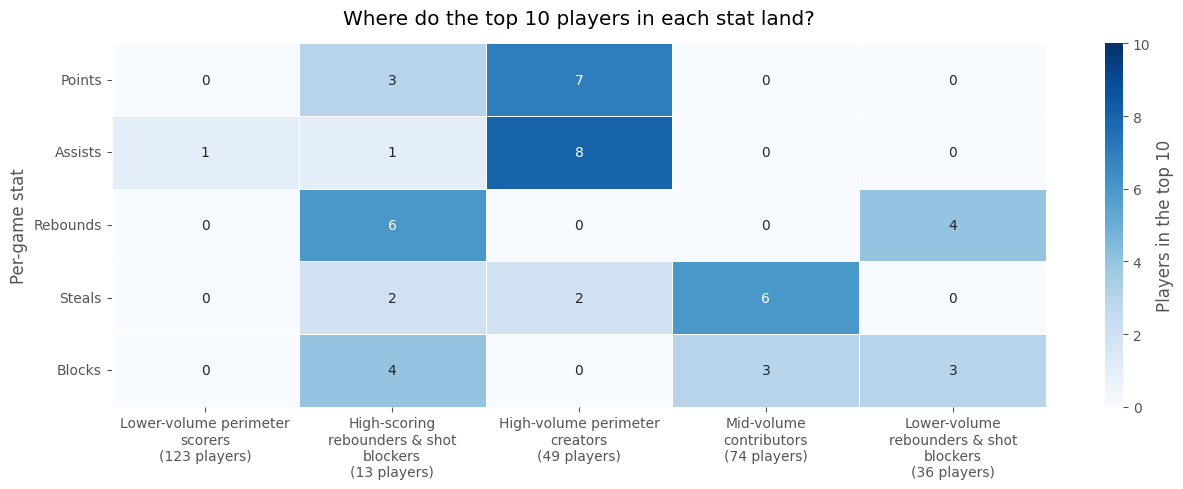

In [150]:
from textwrap import fill

heatmap_players = clustered_players.copy()

# Use total rebounds for the leaderboard.
if "REB" not in heatmap_players.columns:
    heatmap_players["REB"] = heatmap_players["OREB"] + heatmap_players["DREB"]

stats = {
    "Points": "PTS",
    "Assists": "AST",
    "Rebounds": "REB",
    "Steals": "STL",
    "Blocks": "BLK",
}

top_n = 10
cluster_ids = sorted(labels_5)
cluster_sizes = (
    heatmap_players["cluster_5"]
    .value_counts()
    .reindex(cluster_ids, fill_value=0)
)

leaderboards = {}
cluster_counts = {}

for stat_name, column in stats.items():
    # Break ties alphabetically so each leaderboard has at most 10 players.
    top_players = (
        heatmap_players.dropna(subset=[column])
        .sort_values([column, "PLAYER_NAME"], ascending=[False, True])
        .head(top_n)
        [["PLAYER_NAME", column, "cluster_5"]]
        .copy()
    )
    top_players["role_5"] = top_players["cluster_5"].map(labels_5)
    leaderboards[stat_name] = top_players.reset_index(drop=True)

    cluster_counts[stat_name] = (
        top_players["cluster_5"]
        .value_counts()
        .reindex(cluster_ids, fill_value=0)
    )

heatmap_data = pd.DataFrame(cluster_counts).T
heatmap_data.columns = [
    f"{fill(labels_5[cluster_id], width=22)}\n"
    f"({cluster_sizes.loc[cluster_id]} players)"
    for cluster_id in cluster_ids
]

fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=top_n,
    linewidths=0.5,
    cbar_kws={"label": "Players in the top 10", "ticks": range(0, 11, 2)},
    ax=ax,
)

ax.set_title("Where do the top 10 players in each stat land?", pad=14)
ax.set_xlabel("")
ax.set_ylabel("Per-game stat")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
plt.show()

### Where the top 10 players in each stat landed

The heatmap shows how the top 10 players in five per-game stats were distributed across the five clusters. Each leaderboard was ranked within the **295 eligible players** from the 2024–25 regular season.

- **Points and assists.** High-volume perimeter creators accounted for **7 of the top 10 scorers** and **8 of the top 10 in assists**. The other three scoring leaders came from the high-scoring rebounders and shot blockers, showing that top scorers appeared in two distinct player profiles.
- **Rebounds and blocks.** All ten rebounding leaders came from the two rebounding and shot-blocking groups, with **6 in the high-scoring group** and **4 in the lower-volume group**. The high-scoring group contained only **13 of 295 players**, making its share of the rebounding leaderboard especially striking. Blocks were more spread out, with **4** in the high-scoring group, **3** in the lower-volume group, and **3** among mid-volume contributors.
- **Steals.** Mid-volume contributors accounted for **6 of the top 10 in steals** despite making up about **25% of the sample**. Together with their three appearances on the blocks leaderboard, this shows how a group with moderate scoring volume can include players who stand out in specific defensive box-score stats.

The heatmap adds to the cluster averages by showing **where standout individual performances concentrate and where they cut across player profiles**. Because the rankings use stats that went into clustering directly or through their components, the chart is best read as an interpretation of the model. Ties at the cutoff were broken alphabetically, so counts near the cutoff can depend on that choice.

### Stage 1 takeaway

Traditional per-game stats produced recognizable player groupings and surfaced similarities across positions. Those groupings reflect players’ observed production, which depends in part on playing time and team responsibilities. The five-cluster solution gives a more detailed basketball interpretation at the cost of weaker average separation. It provides a reference point for testing whether advanced or possession-adjusted metrics change which players are grouped together.